# 0a_03 The Rules of Probability: Or, And, Not and "At Least One"

**Learning objectives**
- Use the **addition rule**, the **complement rule** and **inclusion-exclusion** for two and three events.
- Define **independent events** and use the **multiplication rule** $P(A\cap B)=P(A)P(B)$.
- Solve **"at least one"** problems with $1-\prod(1-p_i)$ and compute **series and parallel** system reliability.
- Check every rule by simulation and know when a rule does **not** apply.

**Prerequisites:** [0a_01 Outcomes, events and the sample space](0a_01_sets_events_sample_space.ipynb), [0a_02 Counting](0a_02_counting_basics.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, itertools
from matplotlib.patches import Circle, Rectangle

## 2. Prerequisite recap

- An **event** is a set of outcomes; $P(A)$ is a number between 0 and 1 (0a_01).
- $A\cup B$ means "A or B (or both)", $A\cap B$ means "A and B", $A^c$ means "not A".
- For equally likely outcomes $P(A)=|A|/|S|$ and counting tools give $|A|$ (0a_02).
- A **product** $\prod_{i=1}^n x_i=x_1x_2\cdots x_n$.

## 3. Intuition and story

Real questions combine events: "a customer buys **and** returns", "at least one of my three servers is up", "the part passes **both** tests", "**either** the first or the second alarm rings". This lesson gives four rules that turn the probabilities of the simple events into the probability of the combined one:

1. **Not:** $P(A^c)=1-P(A)$.
2. **Or:** $P(A\cup B)=P(A)+P(B)-P(A\cap B)$ (subtract the double count).
3. **And, for independent events:** multiply, $P(A\cap B)=P(A)P(B)$. Independent means that knowing $A$ happened tells you nothing about $B$ (two dice, two separate machines).
4. **At least one:** it is easier to compute the opposite, "none", by multiplying $(1-p_i)$, and subtract from 1.

The most useful trick in elementary probability is #4: "at least one" is almost always $1-P(\text{none})$.

## 4. Formal definitions

| Rule | Statement | When it holds |
|---|---|---|
| **Complement** | $P(A^c)=1-P(A)$ | always |
| **Addition (two events)** | $P(A\cup B)=P(A)+P(B)-P(A\cap B)$ | always |
| **Mutually exclusive** | $P(A\cup B)=P(A)+P(B)$ | $A\cap B=\varnothing$ |
| **Inclusion-exclusion (three events)** | $P(A\cup B\cup C)=P(A)+P(B)+P(C)-P(A\cap B)-P(A\cap C)-P(B\cap C)+P(A\cap B\cap C)$ | always |
| **Independence** | $P(A\cap B)=P(A)\,P(B)$ (this is the *definition*) | a property of the events |
| **Multiplication (independent)** | $P(A_1\cap\cdots\cap A_n)=\prod P(A_i)$ | mutually independent events |
| **At least one** | $P(\text{at least one})=1-\prod_{i}(1-p_i)$ | independent events with probabilities $p_i$ |
| **Union bound (Boole)** | $P(A_1\cup\cdots\cup A_n)\le\sum P(A_i)$ | always |

**Reliability.** Components that must **all** work (**series**) with reliabilities $r_i$ give $\prod r_i$. Redundant components where **at least one** must work (**parallel**) give $1-\prod(1-r_i)$.

## 5. Derivations

### 5.1 Addition rule
Proved in 0a_01 (5.3): $A\cup B$ splits into $A\setminus B$, $A\cap B$, $B\setminus A$; adding $P(A)$ and $P(B)$ counts $A\cap B$ twice. **In plain words.** Add, then subtract the overlap once.

### 5.2 Inclusion-exclusion for three events
Apply the two-event rule to $A\cup(B\cup C)$: $P(A\cup B\cup C)=P(A)+P(B\cup C)-P(A\cap(B\cup C))$. Expand $P(B\cup C)=P(B)+P(C)-P(B\cap C)$ and $A\cap(B\cup C)=(A\cap B)\cup(A\cap C)$, whose probability is $P(A\cap B)+P(A\cap C)-P(A\cap B\cap C)$. Substituting gives the three-event formula. **In plain words.** Add the singles, subtract the pairs (counted twice), add back the triple (which was added three times and subtracted three times, so it vanished).

### 5.3 "At least one" for independent events
"At least one happens" is the complement of "none happens". For independent events $A_i^c$ are also independent (the complement of an independent event stays independent), so $P(\text{none})=\prod(1-p_i)$ and $P(\text{at least one})=1-\prod(1-p_i)$. With $n$ equal events $p$: $1-(1-p)^n$. **In plain words.** To fail to get any, every attempt must fail, and independent failures multiply.

### 5.4 How many attempts to be sure?
Solve $1-(1-p)^n\ge c$: $n\ge\dfrac{\ln(1-c)}{\ln(1-p)}$. **In plain words.** The number of tries grows with $-\ln(1-c)$ but shrinks with the size of $p$; for small $p$, $n\approx\ln(1/(1-c))/p$.

### 5.5 The union bound
$P(A\cup B)=P(A)+P(B)-P(A\cap B)\le P(A)+P(B)$, and by induction the same for $n$ events. **In plain words.** Adding probabilities of overlapping events can only overcount; this is the simplest "safe" upper bound (it is the building block of the concentration bounds in 05_05).

### 5.6 Independent is not the same as exclusive
If $A$ and $B$ are mutually exclusive with positive probabilities, $P(A\cap B)=0\ne P(A)P(B)$, so they are **not** independent: knowing $A$ happened tells you $B$ did not.

## 6. Properties and relationships

- **Series versus parallel:** series systems are *weaker* than their weakest part ($\prod r_i\le\min r_i$); parallel systems are *stronger* than their best part.
- **Diminishing returns:** each extra redundant component multiplies the failure probability by $(1-r)$, but a series part that cannot be duplicated puts a ceiling on the whole system.
- **Independence is an assumption to check,** not a default. Two servers in the same data centre can fail together (a power cut), which breaks the product rule.
- **Large $n$, small $p$:** $1-(1-p)^n\approx1-e^{-np}$, the first appearance of the Poisson distribution (Module 01).
- **Looking ahead:** when events are *not* independent the multiplication rule becomes $P(A\cap B)=P(A)P(B\mid A)$ (0a_04).

## 7. 2D visuals

### 7.1 Three overlapping events (inclusion-exclusion)
The seven regions of a three-circle Venn diagram. Adding the three circles counts the pairwise overlaps twice and the triple overlap three times; inclusion-exclusion corrects it.

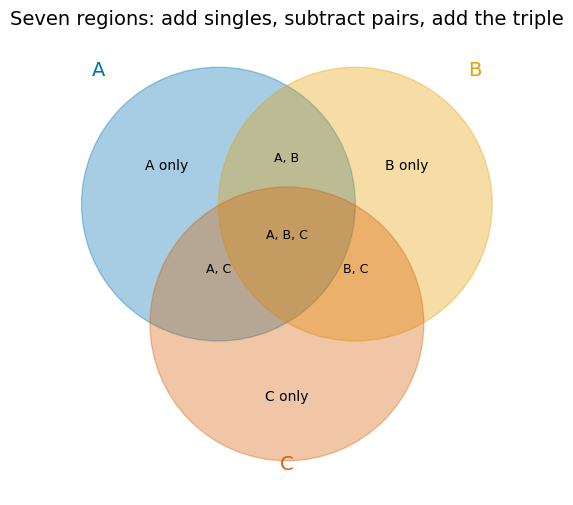

In [2]:
fig, ax = plt.subplots(figsize=(7.5, 6))
for (cx, cy, col, nm) in [(3.2, 3.6, MAIN, "A"), (4.8, 3.6, SIM, "B"), (4.0, 2.2, HIGHLIGHT, "C")]:
    ax.add_patch(Circle((cx, cy), 1.6, facecolor=col, alpha=0.35, edgecolor=col))
    ax.text(cx + (-1.4 if nm == "A" else 1.4 if nm == "B" else 0), cy + (1.5 if nm != "C" else -1.7), nm, fontsize=14, color=col, ha="center")
ax.text(2.6, 4.0, "A only", ha="center"); ax.text(5.4, 4.0, "B only", ha="center"); ax.text(4.0, 1.3, "C only", ha="center")
ax.text(4.0, 4.1, "A, B", ha="center", fontsize=9); ax.text(3.2, 2.8, "A, C", ha="center", fontsize=9); ax.text(4.8, 2.8, "B, C", ha="center", fontsize=9); ax.text(4.0, 3.2, "A, B, C", ha="center", fontsize=9)
ax.set_xlim(1, 7); ax.set_ylim(0.2, 5.6); ax.set_aspect("equal"); ax.axis("off"); ax.set_title("Seven regions: add singles, subtract pairs, add the triple")
plt.show()

### 7.2 "At least one": $1-(1-p)^n$
The chance of at least one success in $n$ independent tries with success chance $p$ each. Small chances accumulate surprisingly fast: with $p=2\,\%$ you need 35 tries to be 50 % sure and 149 to be 95 % sure.

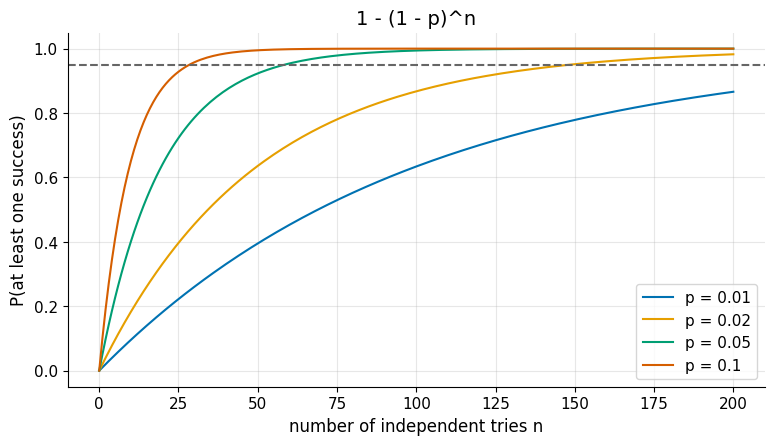

tries needed for a 95 % chance of at least one success: {0.01: 299, 0.02: 149, 0.05: 59, 0.1: 29}


In [3]:
ns = np.arange(0, 201)
fig, ax = plt.subplots(figsize=(9, 4.6))
for pp, c in zip([0.01, 0.02, 0.05, 0.1], COLORS):
    ax.plot(ns, 1 - (1 - pp) ** ns, color=c, label=f"p = {pp}")
ax.axhline(0.95, color=NEUTRAL, linestyle="--"); ax.set_xlabel("number of independent tries n"); ax.set_ylabel("P(at least one success)"); ax.set_title("1 - (1 - p)^n"); ax.legend()
plt.show()
need = {pp: math.ceil(math.log(0.05) / math.log(1 - pp)) for pp in (0.01, 0.02, 0.05, 0.1)}
print("tries needed for a 95 % chance of at least one success:", need)
assert need[0.02] == 149 and math.ceil(math.log(0.5) / math.log(0.98)) == 35

### 7.3 Series and parallel systems
Reliability of a chain of $k$ components in series (all must work) against a bank of $k$ in parallel (one is enough), each component working with probability 0.9.

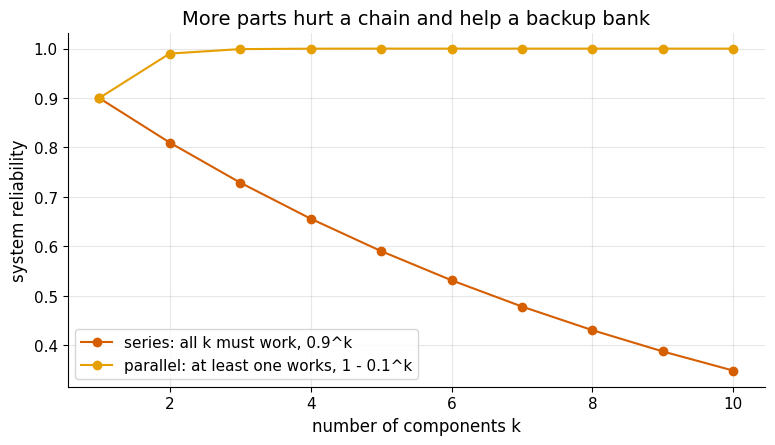

In [4]:
ks = np.arange(1, 11)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(ks, 0.9 ** ks, "o-", color=HIGHLIGHT, label="series: all k must work, 0.9^k")
ax.plot(ks, 1 - 0.1 ** ks, "o-", color=SIM, label="parallel: at least one works, 1 - 0.1^k")
ax.set_xlabel("number of components k"); ax.set_ylabel("system reliability"); ax.set_title("More parts hurt a chain and help a backup bank"); ax.legend()
plt.show()
assert np.isclose(0.9 ** 10, 0.3487, atol=1e-4) and 1 - 0.1 ** 3 == 0.999

### 7.4 Independence on a grid: two dice
For two dice the event "red die is even" and "blue die is at least 5" fill rectangles whose overlap is exactly the product of the sides: the picture of $P(A\cap B)=P(A)P(B)$.

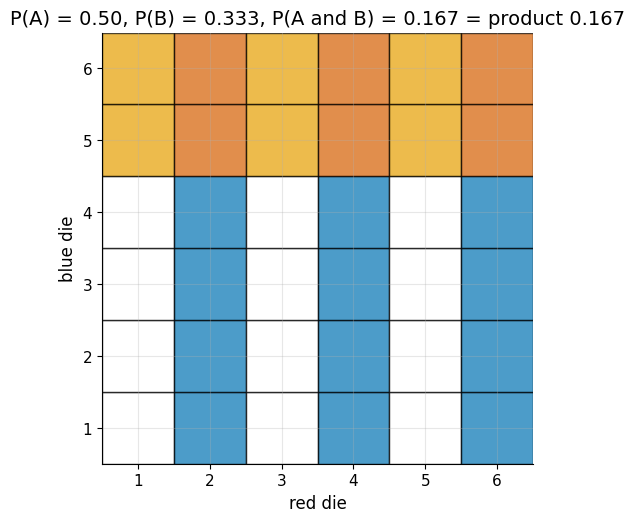

In [5]:
S = list(itertools.product(range(1, 7), range(1, 7)))
EA = {o for o in S if o[0] % 2 == 0}; EB = {o for o in S if o[1] >= 5}
fig, ax = plt.subplots(figsize=(5.8, 5.6))
for r, b in S:
    col = HIGHLIGHT if (r, b) in EA and (r, b) in EB else MAIN if (r, b) in EA else SIM if (r, b) in EB else "white"
    ax.add_patch(Rectangle((r - 0.5, b - 0.5), 1, 1, facecolor=col, edgecolor="black", alpha=0.7))
ax.set_xlim(0.5, 6.5); ax.set_ylim(0.5, 6.5); ax.set_aspect("equal"); ax.set_xlabel("red die"); ax.set_ylabel("blue die")
ax.set_title(f"P(A) = {len(EA) / 36:.2f}, P(B) = {len(EB) / 36:.3f}, P(A and B) = {len(EA & EB) / 36:.3f} = product {len(EA) / 36 * len(EB) / 36:.3f}")
plt.show()
assert np.isclose(len(EA & EB) / 36, len(EA) / 36 * len(EB) / 36)

## 8. 3D visuals

### 8.1 Static: $P(\text{at least one})=1-(1-p)^n$ over $(p,n)$
The surface shows how quickly the chance of at least one success saturates: the steep wall near $p=0$ and large $n$ is the "small chances add up" effect.

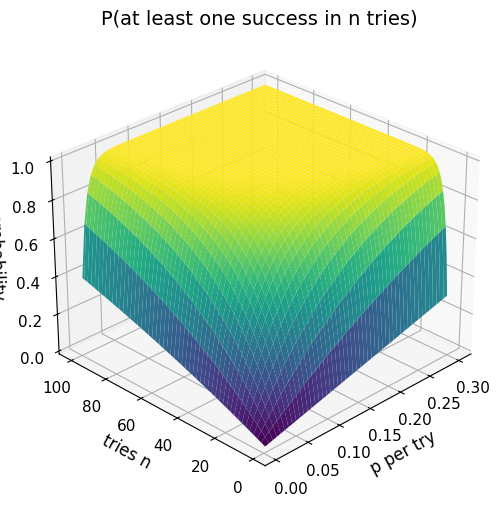

In [6]:
p_ax = np.linspace(0.005, 0.3, 50); n_ax = np.arange(1, 101)
Pg, Ng = np.meshgrid(p_ax, n_ax)
Zs = 1 - (1 - Pg) ** Ng
fig = plt.figure(figsize=(8.5, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(Pg, Ng, Zs, cmap="viridis", edgecolor="none")
ax.set_title("P(at least one success in n tries)"); ax.set_xlabel("p per try"); ax.set_ylabel("tries n"); ax.set_zlabel("probability"); ax.view_init(elev=28, azim=-135)
plt.show()

### 8.2 Interactive Plotly version of 8.1
Hover to read the probability for any $(p,n)$.

In [7]:
fig = go.Figure(go.Surface(x=p_ax, y=n_ax, z=Zs, colorscale="Viridis"))
fig.update_layout(title="1 - (1 - p)^n", width=750, height=550, scene=dict(xaxis_title="p", yaxis_title="n", zaxis_title="probability"))
fig.show()

## 9. Simulation vs theory

### 9.1 The multiplication rule for independent events
Simulate two independent events with $P(A)=0.3$ and $P(B)=0.5$: the joint frequency should be $0.15$. Then make a *dependent* pair (B happens more often when A does) and see the product rule fail.

In [8]:
trials = 400_000
a = rng.random(trials) < 0.3
b_indep = rng.random(trials) < 0.5
b_dep = np.where(a, rng.random(trials) < 0.8, rng.random(trials) < 0.4286)     # B more likely when A happens (overall about 0.5)
print(f"independent: P(A and B) = {(a & b_indep).mean():.4f} vs P(A) P(B) = {a.mean() * b_indep.mean():.4f}")
print(f"dependent:   P(A and B) = {(a & b_dep).mean():.4f} vs P(A) P(B) = {a.mean() * b_dep.mean():.4f}  (rule fails)")
assert abs((a & b_indep).mean() - 0.15) < 0.004 and abs((a & b_dep).mean() - a.mean() * b_dep.mean()) > 0.05

independent: P(A and B) = 0.1501 vs P(A) P(B) = 0.1503
dependent:   P(A and B) = 0.2410 vs P(A) P(B) = 0.1626  (rule fails)


### 9.2 "At least one" by simulation
Ten independent tries with $p=0.2$: the proportion of runs with at least one success against $1-0.8^{10}=0.8926$.

In [9]:
runs = rng.random((200_000, 10)) < 0.2
print(f"simulated {runs.any(axis=1).mean():.4f} | exact {1 - 0.8 ** 10:.4f}")
assert abs(runs.any(axis=1).mean() - (1 - 0.8 ** 10)) < 0.004

simulated 0.8926 | exact 0.8926


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
p_list = np.array([0.7, 0.6, 0.5])
print("P(all three) for independent events: np.prod(p_list) =", np.prod(p_list).round(4))
print("P(at least one): 1 - np.prod(1 - p_list) =", (1 - np.prod(1 - p_list)).round(4))
print("tries for 95 %:", math.ceil(math.log(0.05) / math.log(1 - 0.02)), "| geometric distribution (Module 01) gives the same: stats.geom(0.02).ppf(0.95) =", int(stats.geom(0.02).ppf(0.95)))
print("successes in n tries: stats.binom(n=10, p=0.2).sf(0) = P(at least one) =", stats.binom(10, 0.2).sf(0).round(4))
print("boolean arrays: (a & b).mean() estimates P(A and B); (a | b).mean() estimates P(A or B); (~a).mean() estimates P(not A)")
print("random events: rng.random(size) < p simulates an event of probability p ->", (rng.random(100_000) < 0.3).mean().round(3))

P(all three) for independent events: np.prod(p_list) = 0.21
P(at least one): 1 - np.prod(1 - p_list) = 0.94
tries for 95 %: 149 | geometric distribution (Module 01) gives the same: stats.geom(0.02).ppf(0.95) = 149
successes in n tries: stats.binom(n=10, p=0.2).sf(0) = P(at least one) = 0.8926
boolean arrays: (a & b).mean() estimates P(A and B); (a | b).mean() estimates P(A or B); (~a).mean() estimates P(not A)
random events: rng.random(size) < p simulates an event of probability p -> 0.304


## 11. Real-world worked examples

---
### Example 1 (main): how reliable is a web service with backup servers?

**Scenario.** A website needs three things to work: a **load balancer** (works 99.95 % of the time), at least one of **3 identical web servers** (each works 95 % of the time, independently), and a **database** (99.9 %). All parts fail independently. A year has 8,760 hours.

**Questions**
1. What is the probability that **at least one** of the 3 servers works?
2. What is the reliability of the **whole system**?
3. How many hours of downtime per year is that?
4. How many servers are needed to reach 99.8 % reliability? Can we reach 99.9 % by adding servers?

### 11.1 By hand
**Q1.** All three servers fail with probability $0.05^3=0.000125$, so $P(\text{at least one works})=1-0.000125=0.999875$.

**Q2.** The balancer, the server bank and the database must all work (series): $0.9995\times0.999875\times0.999=0.998376$.

**Q3.** Downtime fraction $1-0.998376=0.001624$, which is $0.001624\times8760\approx14.2$ hours per year.

**Q4.** The balancer and database alone give $0.9995\times0.999=0.9985005$, and the server bank multiplies this by $1-0.05^m$. For 99.8 % we need $1-0.05^m\ge0.998/0.9985005=0.99950$, i.e. $0.05^m\le0.0005$, so $m\ge\ln0.0005/\ln0.05=2.54$: **3 servers** (2 give 0.99600, below target). For 99.9 % no number of servers is enough, because the system can never be better than $0.9985005$: the two parts without backup cap the reliability.

In [11]:
r_lb, r_db, r_srv = 0.9995, 0.999, 0.95
bank = 1 - (1 - r_srv) ** 3
system = r_lb * bank * r_db
print(f"Q1: P(at least one of 3 servers works) = {bank:.6f}")
print(f"Q2: system reliability = {system:.6f}")
print(f"Q3: expected downtime = {(1 - system) * 8760:.1f} hours per year")
for m in range(1, 7):
    print(f"Q4: {m} servers -> reliability {r_lb * r_db * (1 - (1 - r_srv) ** m):.6f}")
need = next(m for m in range(1, 30) if r_lb * r_db * (1 - (1 - r_srv) ** m) >= 0.998)
print(f"servers needed for 99.8 %: {need} | ceiling with infinitely many servers: {r_lb * r_db:.6f}")

Q1: P(at least one of 3 servers works) = 0.999875
Q2: system reliability = 0.998376
Q3: expected downtime = 14.2 hours per year
Q4: 1 servers -> reliability 0.948575
Q4: 2 servers -> reliability 0.996004
Q4: 3 servers -> reliability 0.998376
Q4: 4 servers -> reliability 0.998494
Q4: 5 servers -> reliability 0.998500
Q4: 6 servers -> reliability 0.998500
servers needed for 99.8 %: 3 | ceiling with infinitely many servers: 0.998501


### 11.2 In code with `scipy`, and the asserts

In [12]:
assert np.isclose(bank, 0.999875) and np.isclose(system, 0.99837569, atol=1e-8) and abs((1 - system) * 8760 - 14.23) < 0.01
assert need == 3 and r_lb * r_db * (1 - 0.05 ** 2) < 0.998 and r_lb * r_db < 0.999
assert np.isclose(1 - stats.binom(3, 0.95).pmf(0), bank)                       # at least one of 3: Binomial agrees (Module 01)
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Simulate 2,000,000 years of operation as a snapshot: each part up or down independently, and count how often the system is down.

In [13]:
sim_rng = np.random.default_rng(31)
n_sim = 2_000_000
lb_up = sim_rng.random(n_sim) < r_lb
db_up = sim_rng.random(n_sim) < r_db
srv_up = sim_rng.random((n_sim, 3)) < r_srv
sys_up = lb_up & db_up & srv_up.any(axis=1)
print(f"simulated: bank works {srv_up.any(axis=1).mean():.5f} (exact {bank:.5f}) | system works {sys_up.mean():.5f} (exact {system:.5f}) | downtime {(1 - sys_up.mean()) * 8760:.1f} h/year (exact {(1 - system) * 8760:.1f})")
down = pd.DataFrame({"lb": ~lb_up, "db": ~db_up, "all servers": ~srv_up.any(axis=1)})[~sys_up]
print("share of down snapshots caused by each part (a down snapshot can have several causes):", down.mean().round(3).to_dict())
assert abs(sys_up.mean() - system) < 0.0005 and abs(srv_up.any(axis=1).mean() - bank) < 0.0002

simulated: bank works 0.99988 (exact 0.99987) | system works 0.99842 (exact 0.99838) | downtime 13.9 h/year (exact 14.2)
share of down snapshots caused by each part (a down snapshot can have several causes): {'lb': 0.291, 'db': 0.631, 'all servers': 0.079}


### 11.4 Plots with the regions shaded

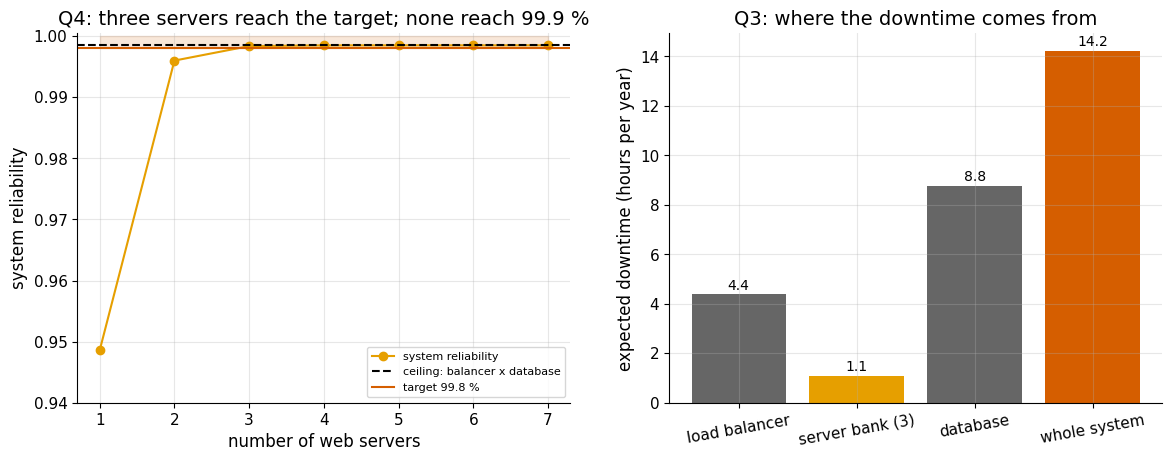

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ms = np.arange(1, 8); rel = r_lb * r_db * (1 - 0.05 ** ms)
axes[0].plot(ms, rel, "o-", color=SIM, label="system reliability")
axes[0].axhline(r_lb * r_db, color="black", linestyle="--", label="ceiling: balancer x database")
axes[0].axhline(0.998, color=HIGHLIGHT, label="target 99.8 %"); axes[0].fill_between(ms, 0.998, 1, color=HIGHLIGHT, alpha=0.15)
axes[0].set_ylim(0.94, 1.0005); axes[0].set_xlabel("number of web servers"); axes[0].set_ylabel("system reliability"); axes[0].set_title("Q4: three servers reach the target; none reach 99.9 %"); axes[0].legend(fontsize=8)
parts = ["load balancer", "server bank (3)", "database", "whole system"]; downtime = [(1 - r_lb) * 8760, (1 - bank) * 8760, (1 - r_db) * 8760, (1 - system) * 8760]
axes[1].bar(parts, downtime, color=[NEUTRAL, SIM, NEUTRAL, HIGHLIGHT]); axes[1].set_ylabel("expected downtime (hours per year)"); axes[1].set_title("Q3: where the downtime comes from")
for i_, d_ in enumerate(downtime): axes[1].text(i_, d_ + 0.2, f"{d_:.1f}", ha="center")
axes[1].tick_params(axis="x", labelrotation=10)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- **Three backup servers are almost perfect:** the bank fails with probability $0.05^3=0.000125$, so at least one server is up 99.9875 % of the time, although each server alone is up only 95 %.
- **The whole system is 99.838 % reliable,** about **14.2 hours of downtime per year**. The simulation (2 million snapshots) gives 99.842 % and 13.9 hours, within random error.
- **The weak points are the parts without backup:** among the simulated down moments the database was down in 63 %, the load balancer in 29 % and the whole server bank in only 8 %.
- **Adding servers has a ceiling.** Two servers give 99.600 %, three 99.838 % (just above the 99.8 % target), a fourth only 99.849 %, and no number of servers can pass 99.8501 % because the balancer and database multiply in series. A target of 99.9 % is impossible without duplicating them.
- **Decision.** Buy the third server (it is cheap and brings the system to the target); to go further, put money into a second database and load balancer, not into more web servers.

---
### Example 2: quality control (at least one defective)

**Scenario.** A factory's items are defective with probability **2 %**, independently. An inspector checks a batch of 10 items. What is the probability of finding **at least one defective**? How many items must be checked to be **95 % sure** of catching at least one?

### 11.6 By hand, in code and by simulation
**By hand.** None defective: $0.98^{10}=0.8171$, so at least one: $1-0.8171=0.1829$. For 95 %: $1-0.98^n\ge0.95\Rightarrow n\ge\dfrac{\ln0.05}{\ln0.98}=148.3$, so **149 items**.

P(at least one defective in 10) = 0.1829 (simulated 0.1834); items for 95 %: 149 (simulated 0.9510 at that size)


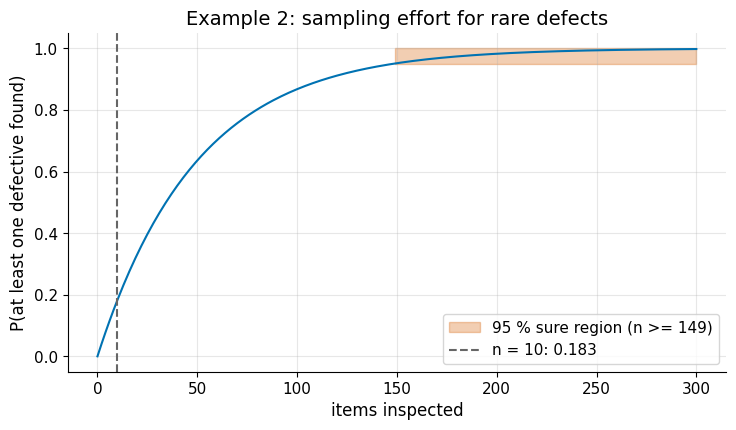

In [15]:
p_def = 0.02
p10 = 1 - (1 - p_def) ** 10
n95 = math.ceil(math.log(0.05) / math.log(1 - p_def))
sim = (np.random.default_rng(4).random((300_000, 10)) < p_def).any(axis=1).mean()
sim149 = (np.random.default_rng(5).random((60_000, n95)) < p_def).any(axis=1).mean()
print(f"P(at least one defective in 10) = {p10:.4f} (simulated {sim:.4f}); items for 95 %: {n95} (simulated {sim149:.4f} at that size)")
assert abs(p10 - 0.1829) < 1e-4 and n95 == 149 and abs(sim - p10) < 0.004 and sim149 >= 0.945
fig, ax = plt.subplots(figsize=(8.5, 4.4))
nn = np.arange(0, 301); ax.plot(nn, 1 - (1 - p_def) ** nn, color=MAIN)
ax.fill_between(nn, 0.95, 1, where=(1 - (1 - p_def) ** nn) >= 0.95, color=HIGHLIGHT, alpha=0.3, label="95 % sure region (n >= 149)")
ax.axvline(10, color=NEUTRAL, linestyle="--", label=f"n = 10: {p10:.3f}"); ax.set_xlabel("items inspected"); ax.set_ylabel("P(at least one defective found)"); ax.set_title("Example 2: sampling effort for rare defects"); ax.legend()
plt.show()

### 11.6b Interpretation and decision (Example 2)
- Checking 10 items finds a defect only **18.3 %** of the time (simulated 18.3 %): inspecting a small sample misses a 2 % defect rate most of the time.
- To be **95 % sure** of finding at least one defective item the inspector must check **149 items** (the simulation at that size gives 95.1 %); for a 1 % defect rate it is 299 items, and for 5 % only 59.
- **Decision.** If the contract promises "we will catch a defect rate of 2 % with 95 % certainty", sample at least 149 items per batch; a batch of 10 gives false comfort.

---
### Example 3: streaming subscriptions (inclusion-exclusion for three groups)

**Scenario.** Of 1,000 households, **500** subscribe to A, **400** to B and **300** to C. Overlaps: **150** have A and B, **100** A and C, **80** B and C, and **40** have all three. How many households subscribe to **at least one** service, and what is the probability that a random household subscribes to **exactly one**?

### 11.7 By hand, in code and by simulation
**By hand.** At least one $=500+400+300-150-100-80+40=\mathbf{910}$, so $P=0.91$ and 90 households have none. Exactly one: A only $=500-150-100+40=290$, B only $=400-150-80+40=210$, C only $=300-100-80+40=160$, total $660$, $P=0.66$.

at least one: 910 (0.91) | none: 90 | only A/B/C: 290/210/160 | exactly one: 660 (0.66) | exactly two: 210 | all three: 40
simulated: at least one 0.9100 | exactly one 0.6614 | P(A) 0.5001


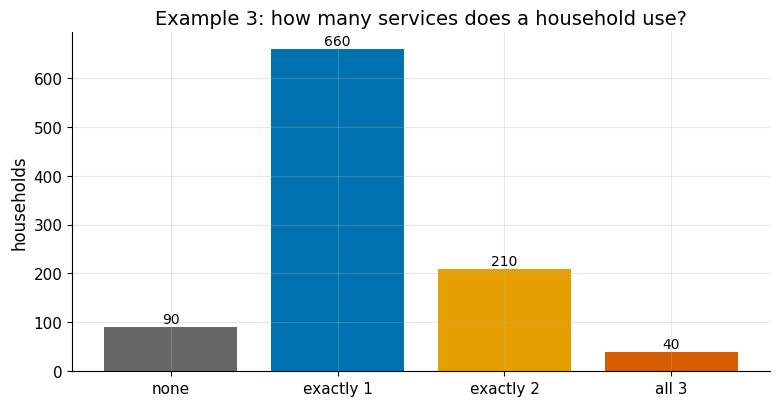

In [16]:
nA, nB, nC, nAB, nAC, nBC, nABC, total = 500, 400, 300, 150, 100, 80, 40, 1000
at_least_one = nA + nB + nC - nAB - nAC - nBC + nABC
only_a, only_b, only_c = nA - nAB - nAC + nABC, nB - nAB - nBC + nABC, nC - nAC - nBC + nABC
exactly_two = (nAB - nABC) + (nAC - nABC) + (nBC - nABC)
print(f"at least one: {at_least_one} ({at_least_one / total:.2f}) | none: {total - at_least_one} | only A/B/C: {only_a}/{only_b}/{only_c} | exactly one: {only_a + only_b + only_c} ({(only_a + only_b + only_c) / total:.2f}) | exactly two: {exactly_two} | all three: {nABC}")
regions = np.array([only_a, only_b, only_c, nAB - nABC, nAC - nABC, nBC - nABC, nABC, total - at_least_one])
assert regions.sum() == total and at_least_one == 910 and only_a + only_b + only_c == 660
# simulate random households from the 8 regions and recompute the totals
codes = np.repeat(np.arange(8), regions)
membership = np.array([[1, 0, 0], [0, 1, 0], [0, 0, 1], [1, 1, 0], [1, 0, 1], [0, 1, 1], [1, 1, 1], [0, 0, 0]])
draw = membership[np.random.default_rng(6).choice(codes, 300_000)]
print(f"simulated: at least one {draw.any(axis=1).mean():.4f} | exactly one {(draw.sum(axis=1) == 1).mean():.4f} | P(A) {draw[:, 0].mean():.4f}")
assert abs(draw.any(axis=1).mean() - 0.91) < 0.004 and abs((draw.sum(axis=1) == 1).mean() - 0.66) < 0.005
fig, ax = plt.subplots(figsize=(9, 4.4))
labels = ["none", "exactly 1", "exactly 2", "all 3"]; vals = [total - at_least_one, only_a + only_b + only_c, exactly_two, nABC]
ax.bar(labels, vals, color=[NEUTRAL, MAIN, SIM, HIGHLIGHT]); ax.set_ylabel("households"); ax.set_title("Example 3: how many services does a household use?")
for i_, v_ in enumerate(vals): ax.text(i_, v_ + 8, str(v_), ha="center")
plt.show()

### 11.7b Interpretation and decision (Example 3)
- **910 of the 1,000 households (91 %)** subscribe to at least one service; adding 500 + 400 + 300 = 1,200 would have counted people several times (more than the 1,000 households).
- **660 (66 %) use exactly one** service (A only 290, B only 210, C only 160), **210 (21 %) use exactly two** and **40 (4 %) use all three**; the remaining **90 (9 %)** use none. A simulation of random households reproduces 91.0 % and 66.1 %.
- **Decision.** The 90 non-subscribers are the target for a promotion, and the 210 households with two services are the best candidates for a bundle that adds the third.

## 12. Where it is used

### Statistics
- **Independence and the product rule** are the foundation of likelihoods (the probability of a data set is a product), of the Binomial distribution and of the standard error ($\sigma/\sqrt n$ comes from independence).
- **Multiple testing:** the chance of at least one false positive among $m$ independent tests is $1-(1-\alpha)^m$; the Bonferroni correction uses the union bound.

### Data science
- **Reliability and SLAs:** uptime of series and parallel components (Example 1); how many redundant services are enough.
- **Funnels and overlaps:** inclusion-exclusion for users in several segments (Example 3); **A/B testing** with many metrics inflates the chance of at least one false win.

### ML and AI
- **Ensembles and redundancy:** the probability that at least one of $n$ independent models or samples is right ($1-(1-p)^n$, as in "best-of-n" sampling); **majority vote** reliability builds on the same product rules.
- **Pipelines in series:** a multi-stage system (retrieval, ranking, generation) works only if every stage works, so end-to-end accuracy is a product of stage accuracies; the union bound drives generalisation bounds (05_05).

## 13. Common pitfalls and misconceptions

- **Multiplying without independence.** $P(A\cap B)=P(A)P(B)$ only holds if the events are independent (two servers in one rack are not).
- **Adding probabilities of overlapping events.** Use the addition rule or "at least one = 1 - none".
- **"Mutually exclusive" is not "independent".** Exclusive events with positive probabilities are strongly dependent.
- **The gambler's fallacy.** After four failures the chance of success on the next independent try is still $p$: independent tries have no memory.
- **Rounding "at least one".** $1-(1-p)^n\ne np$; the sum $np$ can exceed 1 (50 tries at 5 % is not 250 %).
- **Series systems are weaker than their weakest part,** so extra backup on one part cannot fix an unreplicated one (Example 1).
- **Common causes break independence:** shared power, network or software bugs make failures correlated, and the reliability computed with independence is too optimistic.

## 14. Exercises

1. Two machines work independently with reliabilities 0.9 and 0.8. Find the probability that (a) both work, (b) at least one works, (c) exactly one works, (d) neither works.
2. A basketball player scores a free throw with probability 0.75, independently. What is the probability of scoring at least one of 3 shots? Of scoring all 3?
3. A security system has three independent detectors catching an intruder with probabilities 0.7, 0.6 and 0.5. What is the probability that the intruder is caught by at least one? By all three? By exactly one?
4. How many independent emails must a phishing filter check, each being phishing with probability 1 %, to be 90 % sure of seeing at least one phishing email?
5. Events $A$, $B$ have $P(A)=0.5$, $P(B)=0.4$ and $P(A\cup B)=0.7$. Find $P(A\cap B)$. Are $A$ and $B$ independent?
6. (Harder) A two-stage pipeline has stage accuracies 0.95 and 0.9, and each stage fails independently. What is the end-to-end accuracy? Add a third stage of accuracy 0.99: what is the new accuracy? If the first stage stays at 0.95, how accurate must the second stage be for the end-to-end accuracy to reach 0.9?

Solutions are at the end.

## 15. Summary table

| Question | Formula | Condition |
|---|---|---|
| Not $A$ | $1-P(A)$ | always |
| $A$ or $B$ | $P(A)+P(B)-P(A\cap B)$ | always |
| $A$ and $B$ | $P(A)P(B)$ | independent |
| At least one of $n$ | $1-\prod(1-p_i)$ | independent |
| All of $n$ (series) | $\prod p_i$ | independent |
| Tries for confidence $c$ | $\lceil\ln(1-c)/\ln(1-p)\rceil$ | independent equal tries |
| Three events | singles $-$ pairs $+$ triple | always |
| Union bound | $P(\cup A_i)\le\sum P(A_i)$ | always |

## Solutions

In [17]:
r1, r2 = 0.9, 0.8
print(f"1: both {r1 * r2:.2f} | at least one {1 - (1 - r1) * (1 - r2):.2f} | exactly one {r1 * (1 - r2) + (1 - r1) * r2:.2f} | neither {(1 - r1) * (1 - r2):.2f}")
print(f"2: at least one of 3: {1 - 0.25 ** 3:.4f} | all three: {0.75 ** 3:.4f}")
d = np.array([0.7, 0.6, 0.5])
exactly_one = sum(d[i] * np.prod(np.delete(1 - d, i)) for i in range(3))
print(f"3: at least one {1 - np.prod(1 - d):.2f} | all three {np.prod(d):.2f} | exactly one {exactly_one:.3f}")
print("4: n =", math.ceil(math.log(0.1) / math.log(0.99)), "emails")
pab = 0.5 + 0.4 - 0.7
print(f"5: P(A and B) = {pab:.2f}; P(A) P(B) = {0.5 * 0.4:.2f}; independent: {np.isclose(pab, 0.2)}")
print(f"6: two stages {0.95 * 0.9:.3f} | three stages {0.95 * 0.9 * 0.99:.4f} | second stage needed for 0.9 end to end: {0.9 / 0.95:.4f}")

1: both 0.72 | at least one 0.98 | exactly one 0.26 | neither 0.02
2: at least one of 3: 0.9844 | all three: 0.4219
3: at least one 0.94 | all three 0.21 | exactly one 0.290
4: n = 230 emails
5: P(A and B) = 0.20; P(A) P(B) = 0.20; independent: True
6: two stages 0.855 | three stages 0.8464 | second stage needed for 0.9 end to end: 0.9474


**1.** (a) both: $0.9\times0.8=\mathbf{0.72}$; (b) at least one: $1-0.1\times0.2=\mathbf{0.98}$; (c) exactly one: $0.9\times0.2+0.1\times0.8=\mathbf{0.26}$; (d) neither: $0.1\times0.2=\mathbf{0.02}$. (The four cases add to 1.)

**2.** At least one of 3: $1-0.25^3=\mathbf{0.984}$; all three: $0.75^3=\mathbf{0.422}$.

**3.** At least one: $1-0.3\times0.4\times0.5=\mathbf{0.94}$; all three: $0.7\times0.6\times0.5=\mathbf{0.21}$; exactly one: $0.7\cdot0.4\cdot0.5+0.3\cdot0.6\cdot0.5+0.3\cdot0.4\cdot0.5=0.14+0.09+0.06=\mathbf{0.29}$.

**4.** $n\ge\ln0.1/\ln0.99=229.1$, so **230 emails**.

**5.** $P(A\cap B)=0.5+0.4-0.7=\mathbf{0.2}$, and $P(A)P(B)=0.5\times0.4=0.2$: **yes, they are independent**.

**6.** Two stages: $0.95\times0.9=\mathbf{0.855}$. Adding a third stage of 0.99 in series *lowers* the accuracy to $0.855\times0.99=\mathbf{0.846}$ (every stage multiplies the chance of success by a number below 1). For an end-to-end accuracy of 0.9 with the first stage at 0.95, the second stage must reach $0.9/0.95=\mathbf{0.947}$.